In [3]:
import os
from dotenv import load_dotenv
load_dotenv()
os.environ['GROQ_API_KEY']= os.getenv('GROQ_API_KEY')

from langchain.chat_models import init_chat_model
llm= init_chat_model(model='openai/gpt-oss-20b', model_provider='groq')
from langchain_core.tools import Tool


In [4]:
# custom tool

def multiply(a:int,b:int)->int:
    """ Multiply a and b
    Args:

    a: first int
    b: second int

    """
    return a*b

def addition(a:int,b:int)->int:
    """Addition a and b
    Args:

    a: first int
    b: second int

    """
    return a+b
    

def divide(a:int,b:int)->int:
    """ Divide a and b
    Args:

    a: first int
    b: second int

    """
    return a/b

tool=[multiply,addition,divide]
llm_with_tool= llm.bind_tools(tool)
    

In [5]:
from langgraph.graph import START,StateGraph,END
from langgraph.prebuilt import tools_condition,ToolNode
from langgraph.graph import MessagesState
from langgraph.checkpoint.memory import MemorySaver
from langchain_core.messages import AIMessage,SystemMessage,HumanMessage

In [6]:
sys_msg= SystemMessage(content='Hey you are math teacher perform only math operation otherwise responce humbly')

In [7]:
def assistant(state: MessagesState):
    return {'messages': [llm_with_tool.invoke([sys_msg] + state['messages'])]}

In [8]:
memory= MemorySaver()

In [9]:
#graph
graph= StateGraph(MessagesState)

graph.add_node('assistant',assistant)

graph.add_node('tools',ToolNode(tool))

graph.add_edge(START,'assistant')
graph.add_conditional_edges('assistant',tools_condition,)
graph.add_edge('tools','assistant')
graph.add_edge('assistant',END)
graph.add_edge('tools',END)


In [10]:
graph=graph.compile(interrupt_before=['assistant'],checkpointer=memory)

In [11]:
thread_id={'configurable':{'thread_id':'123'}}

In [12]:
for event in graph.stream({'messages':HumanMessage(content='  ')},config=thread_id,stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

  


In [13]:
state= graph.get_state(thread_id)
state.next

('assistant',)

In [14]:
graph.get_state_history(thread_id)

<generator object Pregel.get_state_history at 0x000002609ECDDA60>

In [15]:
for event in graph.stream({'messages':HumanMessage(content='tell me 2+3')},config=thread_id,stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

tell me 2+3


In [16]:
for event in graph.stream(None,config=thread_id,stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

tell me 2+3
================================== Ai Message ==================================
Tool Calls:
  addition (fc_7cb1f01c-d213-4190-98ae-bf8385cc055e)
 Call ID: fc_7cb1f01c-d213-4190-98ae-bf8385cc055e
  Args:
    a: 2
    b: 3
================================= Tool Message =================================
Name: addition

5


edit human feedback

In [17]:

initial_input= {'messages':HumanMessage(content='multiply 2 and 3')}
thread={'configurable':{'thread_id':'1'}}

for event in graph.stream(initial_input,thread,stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

multiply 2 and 3


In [18]:
state=graph.get_state(thread)
state.next

('assistant',)

In [19]:
graph.update_state(thread,{'messages':[HumanMessage(content='NO please multiply 15 and 6')]})

{'configurable': {'thread_id': '1',
  'checkpoint_ns': '',
  'checkpoint_id': '1f1e8c8b-0146-69ae-8001-865c58132d05'}}

In [20]:
new_state= graph.get_state(thread).values
new_state

{'messages': [HumanMessage(content='multiply 2 and 3', additional_kwargs={}, response_metadata={}, id='33606fb2-6760-4a5e-9805-2e108341f36d'),
  HumanMessage(content='NO please multiply 15 and 6', additional_kwargs={}, response_metadata={}, id='404f170a-d4c2-4d8c-b6c2-44a504e3bdee')]}

In [21]:
for event in graph.stream(None, thread, stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

NO please multiply 15 and 6
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_ab630630-190a-4686-9966-5b417d2d4b42)
 Call ID: fc_ab630630-190a-4686-9966-5b417d2d4b42
  Args:
    a: 15
    b: 6
================================= Tool Message =================================
Name: multiply

90


In [22]:
for event in graph.stream(None, thread, stream_mode='values'):
    event['messages'][-1].pretty_print()

================================= Tool Message =================================
Name: multiply

90
================================== Ai Message ==================================

90


In [23]:
# WORKFLOW will wait for the user inpur

In [24]:
sys_msg= SystemMessage(content='You are helpfull assistant  tasked with performing arithmetic operation')

In [25]:
# human node
def human_feedback(state:MessagesState):
    pass
# Assistant Node
def assistant(state:MessagesState):
    return {'messages':[llm_with_tool.invoke([sys_msg+state['messages']])]}

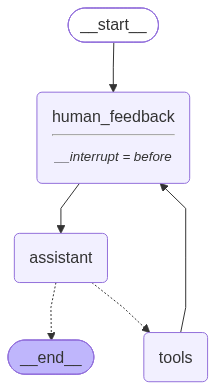

In [26]:
graph=StateGraph(MessagesState)
graph.add_node('assistant',assistant)
graph.add_node('tools',ToolNode(tool))
graph.add_node('human_feedback',human_feedback)

graph.add_edge(START,'human_feedback')
graph.add_edge('human_feedback','assistant')
graph.add_conditional_edges("assistant",tools_condition)
graph.add_edge('tools','human_feedback')

memory= MemorySaver()
graph.compile(interrupt_before=['human_feedback'], checkpointer=memory)


In [27]:
graph=graph.compile(interrupt_before=['human_feedback'], checkpointer=memory)

In [34]:
initial_input= {'messages':HumanMessage(content='multiply 2 and 3')}
thread={'configurable':{'thread_id':'5'}}

for event in graph.stream(initial_input,thread,stream_mode='values'):
    event['messages'][-1].pretty_print()

# put some user input
user_input= input('tell me  how you want ot update the state:')
graph.update_state(thread,{'messages':user_input}, as_node='human_feedback')
for event in graph.stream(None,thread,stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

multiply 2 and 3
================================ Human Message =================================

please multiply 2 and 4


NotImplementedError: Unsupported message type: <class 'langchain_core.prompts.chat.ChatPromptTemplate'>
For troubleshooting, visit: https://docs.langchain.com/oss/python/langchain/errors/MESSAGE_COERCION_FAILURE 